In [ ]:
import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt
import mne


In [ ]:
data = sio.loadmat('data/S1.mat')['data']          # (64, 1500, 40, 6)
fp = sio.loadmat('data/Freq_Phase.mat')
freqs = fp['freqs'].flatten()                      
print(data.shape)
print(freqs)                                       

(64, 1500, 40, 6)
[ 8.   9.  10.  11.  12.  13.  14.  15.   8.2  9.2 10.2 11.2 12.2 13.2
 14.2 15.2  8.4  9.4 10.4 11.4 12.4 13.4 14.4 15.4  8.6  9.6 10.6 11.6
 12.6 13.6 14.6 15.6  8.8  9.8 10.8 11.8 12.8 13.8 14.8 15.8]


In [ ]:
ch_names = []
with open('data/64-channels.loc') as f:
    for line in f:
        parts = line.split()
        if len(parts) >= 4:
            ch_names.append(parts[3])
print(len(ch_names))                               


64


In [40]:
X = data.transpose(2, 3, 0, 1).reshape(240, 64, 1500)
labels = np.repeat(np.arange(40), 6)
info = mne.create_info(ch_names, sfreq=250, ch_types='eeg')
events = np.column_stack([np.arange(240), np.zeros(240, int), labels])
epochs = mne.EpochsArray(X * 1e-6, info, events=events, tmin=-0.5)
epochs.drop_channels(['CB1', 'CB2'])
epochs.set_montage(mne.channels.make_standard_montage('standard_1005'),
                   match_case=False)


Not setting metadata
240 matching events found
No baseline correction applied
0 projection items activated


C:\Users\Samar\AppData\Local\Temp\ipykernel_3700\4148372086.py:7: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  epochs.set_montage(mne.channels.make_standard_montage('standard_1005'),


<EpochsArray | 240 events (all good), -0.5 – 5.496 s (baseline off), ~170.4 MiB, data loaded,
 '0': 6
 '1': 6
 '2': 6
 '3': 6
 '4': 6
 '5': 6
 '6': 6
 '7': 6
 '8': 6
 '9': 6
 and 30 more events ...>

In [41]:
wanted = ['POz', 'Oz', 'O1', 'O2', 'PO3', 'PO4', 'PO5', 'PO6', 'Pz']
lookup = {n.upper(): n for n in epochs.ch_names}
picks = [lookup[w.upper()] for w in wanted if w.upper() in lookup]
epochs_occ = epochs.copy().pick(picks)

d = epochs_occ.get_data()
d = mne.filter.notch_filter(d, Fs=250, freqs=50, notch_widths=2,
                            trans_bandwidth=2)
epochs_occ = mne.EpochsArray(d, epochs_occ.info, events=epochs_occ.events,
                             tmin=-0.5)
epochs_occ.filter(6, 90);


Setting up band-stop filter from 48 - 52 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 48.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 47.50 Hz)
- Upper passband edge: 52.00 Hz
- Upper transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 52.50 Hz)
- Filter length: 825 samples (3.300 s)

Not setting metadata
240 matching events found
No baseline correction applied
0 projection items activated
Setting up band-pass filter from 6 - 90 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 6.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 5.00 Hz)
-

Effective window size : 4.096 (s)
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


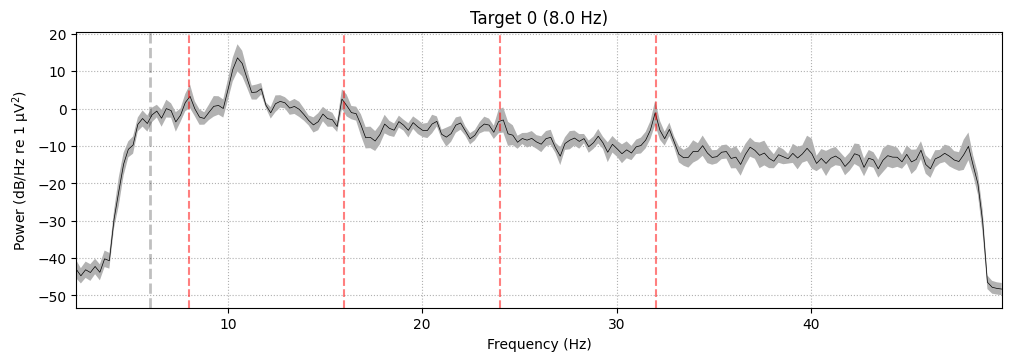

Effective window size : 4.096 (s)
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


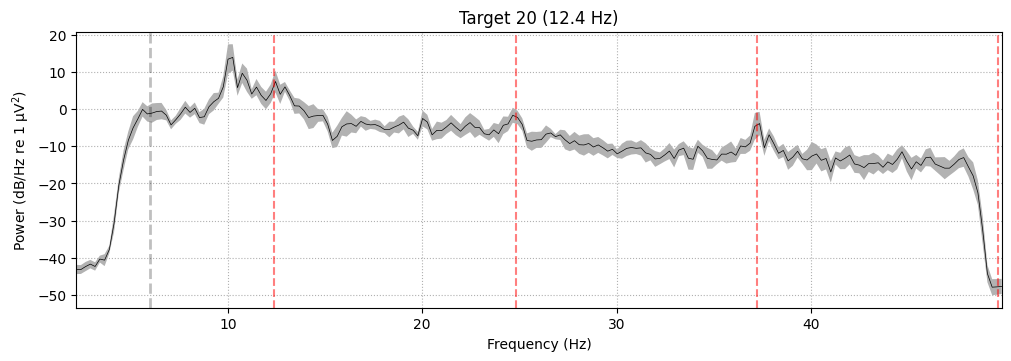

Effective window size : 4.096 (s)
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


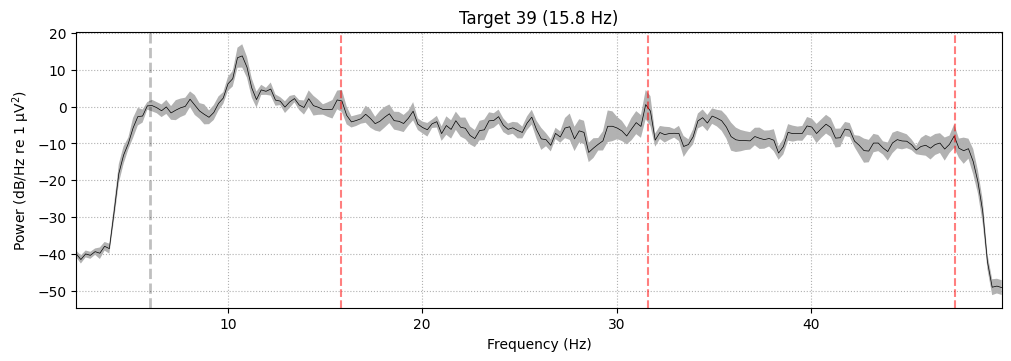

In [43]:
for target in [0, 20, 39]:
    f0 = freqs[target]
    spec = epochs_occ[str(target)].compute_psd(
        method='welch', fmin=2, fmax=50, tmin=0.64, tmax=5.49, n_fft=1024)
    fig = spec.plot(average=True, show=False)
    ax = fig.axes[0]
    ax.set_title(f'Target {target} ({f0} Hz)')
    for k in (1, 2, 3, 4):                 # flicker + harmonics
        ax.axvline(k * f0, color='r', ls='--', alpha=0.5)
    plt.show()